<a href="https://colab.research.google.com/github/lsof-ctrl/N6429_CreateSQLPythonDataPipeline/blob/main/Week13_Pipeline_Starter_LSOF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 13 SQL–Python Pipeline

Place your `community_followup.sqlite` file in the same folder as this notebook. Complete each TODO and document the intended grain of every query.


In [7]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = Path("/content/community_followup.sqlite")

assert DB_PATH.exists(), f"Database not found: {DB_PATH.resolve()}"

print("Database found successfully!")


Database found successfully!


## 1 Connect and inspect tables


In [9]:
connection = sqlite3.connect(DB_PATH)
connection.execute("PRAGMA foreign_keys = ON")

# Intended grain: One row per database table.
# Purpose: Confirm that all five expected tables exist.

query = """
SELECT name
FROM sqlite_schema
WHERE type = 'table'
ORDER BY name;
"""

tables = pd.read_sql_query(query, connection)
display(tables)

expected_tables = {
    "clinics", "encounters", "followups",
    "patients", "referrals"
}

assert set(tables["name"]) == expected_tables, \
    "Database tables do not match the expected five tables."

print("Success! All five expected tables exist.")


,name
0,clinics
1,encounters
2,followups
3,patients
4,referrals


Success! All five expected tables exist.


## 2 Referral-level extract

**Intended grain:** one row per referral.


In [11]:
referral_query = """
SELECT
    r.referral_id,
    c.clinic_name,
    r.service_type,
    r.due_date,
    f.completion_date,
    p.social_needs_flag,
    f.outcome,
    f.contact_attempts
FROM referrals AS r
JOIN encounters AS e
    ON r.encounter_id = e.encounter_id
JOIN clinics AS c
    ON e.clinic_id = c.clinic_id
JOIN patients AS p
    ON e.patient_id = p.patient_id
LEFT JOIN followups AS f
    ON r.referral_id = f.referral_id
"""

referrals = pd.read_sql_query(referral_query, connection)
display(referrals.head())

,referral_id,clinic_name,service_type,due_date,completion_date,social_needs_flag,outcome,contact_attempts
0,R001,Northside Clinic,Medication review,2026-08-17,2026-08-13,1,Completed on time,1
1,R002,Riverbend Clinic,Social work,2026-08-19,2026-08-18,0,Completed on time,2
2,R003,Mountain View Clinic,Nutrition,2026-08-14,2026-08-14,0,Completed on time,3
3,R004,Northside Clinic,Care coordination,2026-08-23,2026-08-21,0,Completed on time,1
4,R005,Riverbend Clinic,Medication review,2026-08-25,2026-08-26,1,Completed late,2


In [12]:
print("Total rows:", len(referrals))
print("Unique referrals:", referrals["referral_id"].nunique())

Total rows: 40
Unique referrals: 40


## 3 Validate the extract


In [13]:
# TODO: Validate the referral-level extract
# Intended grain: One row per referral

# 1. Confirm expected row count
assert len(referrals) == 40, "Expected 40 referrals."

# 2. Confirm each referral_id is unique
assert referrals["referral_id"].is_unique, \
    "Duplicate referral IDs found."

# 3. Confirm clinic_name is not missing
assert referrals["clinic_name"].notna().all(), \
    "Missing clinic names found."

print("All three validation checks passed!")

All three validation checks passed!


## 4 Transform and summarize


In [14]:
def add_completion_fields(frame):
    # Intended grain: One row per referral

    # Create a copy of the DataFrame
    frame = frame.copy()

    # Convert date columns to datetime
    frame["due_date"] = pd.to_datetime(frame["due_date"])
    frame["completion_date"] = pd.to_datetime(frame["completion_date"])

    # Create completed field
    frame["completed"] = frame["completion_date"].notna()

    # Create on_time field
    frame["on_time"] = (
        frame["completed"] &
        (frame["completion_date"] <= frame["due_date"])
    )

    return frame


# Apply the function
analysis = add_completion_fields(referrals)

# Intended grain: One row per clinic
# Create clinic summary with referral counts and on-time rate

clinic_summary = (
    analysis.groupby("clinic_name")
    .agg(
        referral_count=("referral_id", "count"),
        on_time_rate=("on_time", "mean")
    )
    .reset_index()
)

# Convert on-time rate to percentage
clinic_summary["on_time_rate"] = (
    clinic_summary["on_time_rate"] * 100
)

display(clinic_summary)


,clinic_name,referral_count,on_time_rate
0,Mountain View Clinic,13,23.076923
1,Northside Clinic,14,85.714286
2,Riverbend Clinic,13,38.461538


## 5 Visualization and interpretation


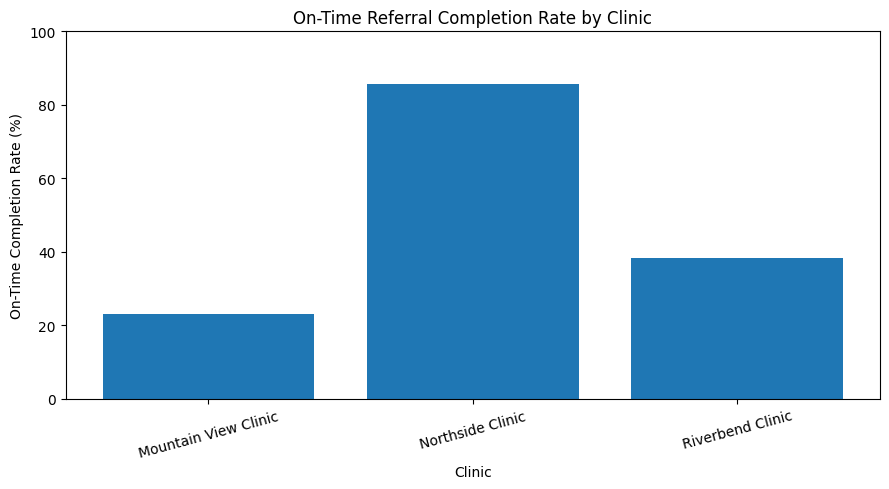

In [15]:
# Section 5: Visualization and Interpretation
# Intended grain: One bar per clinic

plt.figure(figsize=(9, 5))

plt.bar(
    clinic_summary["clinic_name"],
    clinic_summary["on_time_rate"]
)

plt.title("On-Time Referral Completion Rate by Clinic")
plt.xlabel("Clinic")
plt.ylabel("On-Time Completion Rate (%)")
plt.ylim(0, 100)

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Interpretation and limitation:**

Interpretation: The graph shows that the three clinics had different rates of completing referrals on time. Northside Clinic had the highest rate at 85.71%, followed by Riverbend Clinic at 38.46% and Mountain View Clinic at 23.08%. Although all three clinics had about the same number of referrals, some completed more referrals on time than others. This suggests that we should look into what might be causing delays and how we can improve the follow-up process.

Limitation: One limitation is that each clinic had only 13–14 referrals included in the data. Since this is a small sample, the results may not fully show how each clinic performs over time.


## 6 Second SQL query

Write a grouped SQL query by clinic or service. Compare it with the Pandas summary and explain any difference.


In [16]:
# Intended grain: One row per clinic
# Purpose: Calculate referral counts and on-time completion rates

summary_query = """
SELECT
    c.clinic_name,
    COUNT(r.referral_id) AS referral_count,
    ROUND(
        100.0 * AVG(
            CASE
                WHEN f.completion_date IS NOT NULL
                AND date(f.completion_date) <= date(r.due_date)
                THEN 1.0
                ELSE 0.0
            END
        ), 2
    ) AS on_time_rate
FROM referrals AS r
JOIN encounters AS e
    ON r.encounter_id = e.encounter_id
JOIN clinics AS c
    ON e.clinic_id = c.clinic_id
LEFT JOIN followups AS f
    ON r.referral_id = f.referral_id
GROUP BY c.clinic_name
ORDER BY c.clinic_name;
"""

sql_summary = pd.read_sql_query(summary_query, connection)
display(sql_summary)


,clinic_name,referral_count,on_time_rate
0,Mountain View Clinic,13,23.08
1,Northside Clinic,14,85.71
2,Riverbend Clinic,13,38.46


In [17]:
display(clinic_summary)
display(sql_summary)

,clinic_name,referral_count,on_time_rate
0,Mountain View Clinic,13,23.076923
1,Northside Clinic,14,85.714286
2,Riverbend Clinic,13,38.461538


,clinic_name,referral_count,on_time_rate
0,Mountain View Clinic,13,23.08
1,Northside Clinic,14,85.71
2,Riverbend Clinic,13,38.46


The SQL query and Pandas summary gave the same results. Both showed that Northside Clinic had the highest on-time referral completion rate, followed by Riverbend Clinic and Mountain View Clinic. The main difference is that SQL calculates the results directly from the database, while Pandas uses Python to analyze the data. Both methods can be used to get the same information.

## 7 AI use and verification

Document the task, prompt, response, test, correction, and judgment.


Task: I used AI to help complete my SQL assignment, including joining database tables, validating the data, and calculating referral completion rates.

Prompt: I asked ChatGPT to help me verify the TODO sections of my assignment and explain the SQL and Python code in simpler terms.

AI Response: ChatGPT provided code examples for joining the five tables, checking referral data, calculating on-time completion rates, and comparing SQL and Pandas summaries.

Test: I ran the code in Google Colab and reviewed the results. I confirmed that the dataset contained 40 rows with 40 unique referral IDs. I also reviewed the completion rates for the three clinics.

Correction: I corrected the database file path so the notebook could locate the SQLite file. I also reviewed the suggested code and made sure it followed the assignment instructions.

Judgment: AI helped me better understand SQL and Python and made it easier to verify if I completed the assignment correctly. Still a learning process, but we are getting there.


In [18]:
connection.close()
print("Connection closed.")


Connection closed.
